# Beyond the Average

## Variability in Reported Sexual Assault Victimisation Rates Across Australian States (1993–2024)

In previous notebooks we developed variance from first principles.

Now we'll use that idea to answer a real statistical question using official data from the Australian Bureau of Statistics (ABS).

Instead of asking

> Which state has the highest reported victimisation rate?

we'll ask

> Which states have the most consistent—and the most variable—reported victimisation rates over time?

This distinction is important because averages alone often hide important patterns.

# Learning Objectives

By the end of this notebook, you will be able to:

- Work with a real Australian government dataset.
- Perform exploratory data analysis (EDA).
- Compute and compare average crime rates across states.
- Use variance to measure the consistency of crime over time.
- Interpret variance in a real-world context.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [6]:
df = pd.read_excel(
    "../data/crime_data.xlsx",
    sheet_name="Table 10",
    header=None
)

In [7]:
df.head(20)

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
0,This table shows Victimisation rates from 1993...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Australian Bureau of Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Table 10 Victimisation rates(a), Selected offe...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Recorded Crime – Victims, 2024",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Offence,1993,1994,1995,1996,1997,1998,1999(b),2000,2001,...,2015,2016,2017(i),2018(i),2019(i),2020(i),2021(i),2022,2023,2024
6,NaN,New South Wales,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Homicide and related offences(j),3.4,2.9,2.7,3.2,3.5,3.8,4.2,4.1,4.8,...,1.4,1.3,1,1.3,1.4,1.2,1,1,0.9,1.5
8,Murder,2,1.8,1.7,1.5,1.8,1.5,1.9,1.5,1.6,...,0.9,0.8,0.6,0.9,0.9,0.8,0.7,0.7,0.7,1
9,Attempted murder,1.4,1,0.9,1.4,1.6,1.9,2.1,2.3,3.2,...,0.4,0.3,0.2,0.3,0.3,0.3,0.3,0.1,0.2,0.4


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column                                                                                                                                     Non-Null Count  Dtype 
---  ------                                                                                                                                     --------------  ----- 
 0   This tab outlines the contents of the datacube and includes links to relevant webpages on the ABS website. It ranges from cell A1 to B21.  20 non-null     object
 1   Unnamed: 1                                                                                                                                 9 non-null      object
dtypes: object(2)
memory usage: 452.0+ bytes


## Understanding the Dataset

Government datasets are rarely analysis-ready.

Before writing any code, it's important to understand how the information is organised.

Looking at the spreadsheet, we immediately notice three things.

1. Years appear across the columns.
2. States appear as section headings.
3. Offence categories appear beneath each state.

Our first task is to transform this into a tidy dataset suitable for statistical analysis.

In [9]:
df.head(20)

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
0,This table shows Victimisation rates from 1993...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Australian Bureau of Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Table 10 Victimisation rates(a), Selected offe...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Recorded Crime – Victims, 2024",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Offence,1993,1994,1995,1996,1997,1998,1999(b),2000,2001,...,2015,2016,2017(i),2018(i),2019(i),2020(i),2021(i),2022,2023,2024
6,NaN,New South Wales,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Homicide and related offences(j),3.4,2.9,2.7,3.2,3.5,3.8,4.2,4.1,4.8,...,1.4,1.3,1,1.3,1.4,1.2,1,1,0.9,1.5
8,Murder,2,1.8,1.7,1.5,1.8,1.5,1.9,1.5,1.6,...,0.9,0.8,0.6,0.9,0.9,0.8,0.7,0.7,0.7,1
9,Attempted murder,1.4,1,0.9,1.4,1.6,1.9,2.1,2.3,3.2,...,0.4,0.3,0.2,0.3,0.3,0.3,0.3,0.1,0.2,0.4


In [8]:
years = list(df.iloc[5, 1:33])
years

[1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 '1999(b)',
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 '2007(c)',
 '2008(d)',
 '2009(e)(f)',
 '2010(g)(h)',
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 '2017(i)',
 '2018(i)',
 '2019(i)',
 '2020(i)',
 '2021(i)',
 2022,
 2023,
 2024]

### Algorithm

We'll scan through the spreadsheet row by row.

Whenever we encounter a state heading, we'll remember it.

Whenever we encounter the offence "Sexual assault", we'll pair that row with the most recently seen state.

This allows us to automatically extract the information for every Australian state and territory.

In [25]:
states = [
    "New South Wales",
    "Victoria(m)",
    "Queensland",
    "South Australia",
    "Western Australia",
    "Tasmania(r)",
    "Northern Territory(t)(u)(v)",
    "Australian Capital Territory"
]

In [26]:
df.head(20)

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
0,This table shows Victimisation rates from 1993...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Australian Bureau of Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Table 10 Victimisation rates(a), Selected offe...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Recorded Crime – Victims, 2024",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Offence,1993,1994,1995,1996,1997,1998,1999(b),2000,2001,...,2015,2016,2017(i),2018(i),2019(i),2020(i),2021(i),2022,2023,2024
6,NaN,New South Wales,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Homicide and related offences(j),3.4,2.9,2.7,3.2,3.5,3.8,4.2,4.1,4.8,...,1.4,1.3,1,1.3,1.4,1.2,1,1,0.9,1.5
8,Murder,2,1.8,1.7,1.5,1.8,1.5,1.9,1.5,1.6,...,0.9,0.8,0.6,0.9,0.9,0.8,0.7,0.7,0.7,1
9,Attempted murder,1.4,1,0.9,1.4,1.6,1.9,2.1,2.3,3.2,...,0.4,0.3,0.2,0.3,0.3,0.3,0.3,0.1,0.2,0.4


In [27]:
current_state = None

records = []

for _, row in df.iterrows():
    assault_cell = row[0]
    state_cell = row[1]
    #Detect a state heading
    if state_cell in states:
        current_state = state_cell
        continue
    
    #Detect the offence we want
    if assault_cell == "Sexual assault":
        rates = row[1:33].tolist()
    
        for year,rate in zip(years, rates):

            records.append({
                "State": current_state,
                "Year": int(str(year)[:4]),
                "Victimisation Rate": rate
            })
sexual_assault_df = pd.DataFrame(records)

In [28]:
sexual_assault_df.head(20)

,State,Year,Victimisation Rate
0,New South Wales,1993,63.3
1,New South Wales,1994,76.3
2,New South Wales,1995,68.1
3,New South Wales,1996,81.6
4,New South Wales,1997,74.6
5,New South Wales,1998,71.4
6,New South Wales,1999,69.4
7,New South Wales,2000,92.7
8,New South Wales,2001,96.0
9,New South Wales,2002,98.4


In [29]:
sexual_assault_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   State               224 non-null    object 
 1   Year                224 non-null    int64  
 2   Victimisation Rate  224 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 5.4+ KB


In [30]:
sexual_assault_df.describe()

,Year,Victimisation Rate
count,224.000000,224.000000
mean,2008.500000,91.110268
std,9.253772,37.538599
min,1993.000000,24.000000
25%,2000.750000,64.850000
50%,2008.500000,89.600000
75%,2016.250000,107.100000
max,2024.000000,197.800000


In [31]:
sexual_assault_df.isna().sum()

State                 0
Year                  0
Victimisation Rate    0
dtype: int64

## Why Did We Reshape the Data?

The original spreadsheet was designed for people to read.

The tidy DataFrame is designed for statistical analysis.

Notice how much easier it will now be to:

- calculate averages,
- compute variance,
- create visualisations,
- compare states,
- perform further statistical analyses.

Cleaning and restructuring data is often the most time-consuming part of a real data science project, but it lays the foundation for everything that follows.

# Exploratory Data Analysis

Before calculating any statistics, it's important to understand the data.

We'll ask a few simple questions:

- Which years are covered?
- Which states are included?
- How many observations do we have?
- What does the distribution of victimisation rates look like?

EDA helps us build intuition before moving on to statistical analysis.

In [32]:
print(f"Number of observations : {len(sexual_assault_df)}")

print()

print(f"States:")
print(sexual_assault_df["State"].unique())

print()

print(f"Years:")
print(sexual_assault_df["Year"].min(), "-", sexual_assault_df["Year"].max())

Number of observations : 224

States:
['New South Wales' 'Victoria(m)' 'Queensland' 'South Australia'
 'Tasmania(r)' 'Northern Territory(t)(u)(v)'
 'Australian Capital Territory']

Years:
1993 - 2024


In [33]:
sexual_assault_df.describe()

,Year,Victimisation Rate
count,224.000000,224.000000
mean,2008.500000,91.110268
std,9.253772,37.538599
min,1993.000000,24.000000
25%,2000.750000,64.850000
50%,2008.500000,89.600000
75%,2016.250000,107.100000
max,2024.000000,197.800000


The summary statistics provide a first glimpse into the dataset.

Notice the range of victimisation rates.

Some years record substantially higher rates than others, suggesting that the variability may differ across states.

We'll investigate this more formally using variance shortly.

# Visualising Trends Over Time

Before calculating averages or variances, let's simply look at how the reported victimisation rates change over time.

Patterns that are difficult to spot in a table often become immediately obvious in a graph.

In [34]:
sexual_assault_df.head(20)

,State,Year,Victimisation Rate
0,New South Wales,1993,63.3
1,New South Wales,1994,76.3
2,New South Wales,1995,68.1
3,New South Wales,1996,81.6
4,New South Wales,1997,74.6
5,New South Wales,1998,71.4
6,New South Wales,1999,69.4
7,New South Wales,2000,92.7
8,New South Wales,2001,96.0
9,New South Wales,2002,98.4


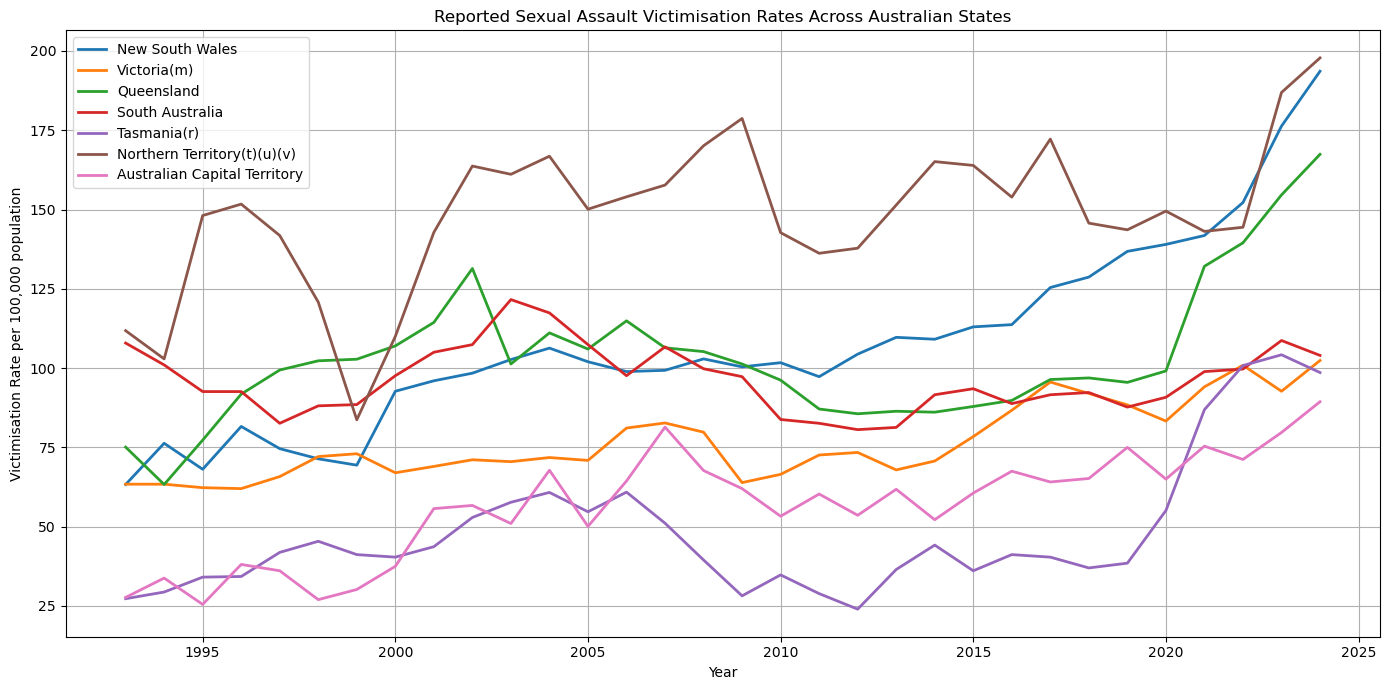

In [35]:
plt.figure(figsize=(14,7))

for state in sexual_assault_df["State"].unique():
    state_data = sexual_assault_df[
        sexual_assault_df["State"] == state
    ]
    plt.plot(
        state_data["Year"],
        state_data["Victimisation Rate"],
        linewidth=2,
        label=state
    )

plt.title("Reported Sexual Assault Victimisation Rates Across Australian States")

plt.xlabel("Year")
plt.ylabel("Victimisation Rate per 100,000 population")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig("../images/sexual_assault_trends.png", dpi=300)

plt.show()


## Initial Observations

Even before calculating any statistics, several interesting patterns emerge.

Some states exhibit relatively smooth changes over time.

Others experience much larger fluctuations.

At this stage, we're relying only on visual intuition.

In the next section, we'll quantify these differences using the mean and variance.

Which state has the highest average victimisation rate?

In [36]:
mean_rates = (
    sexual_assault_df
    .groupby("State")["Victimisation Rate"]
    .mean()
    .sort_values(ascending=False)
)

mean_rates

State
Northern Territory(t)(u)(v)     148.437500
New South Wales                 107.718750
Queensland                      103.487500
South Australia                  96.468750
Victoria(m)                      76.731250
Australian Capital Territory     56.468750
Tasmania(r)                      48.459375
Name: Victimisation Rate, dtype: float64

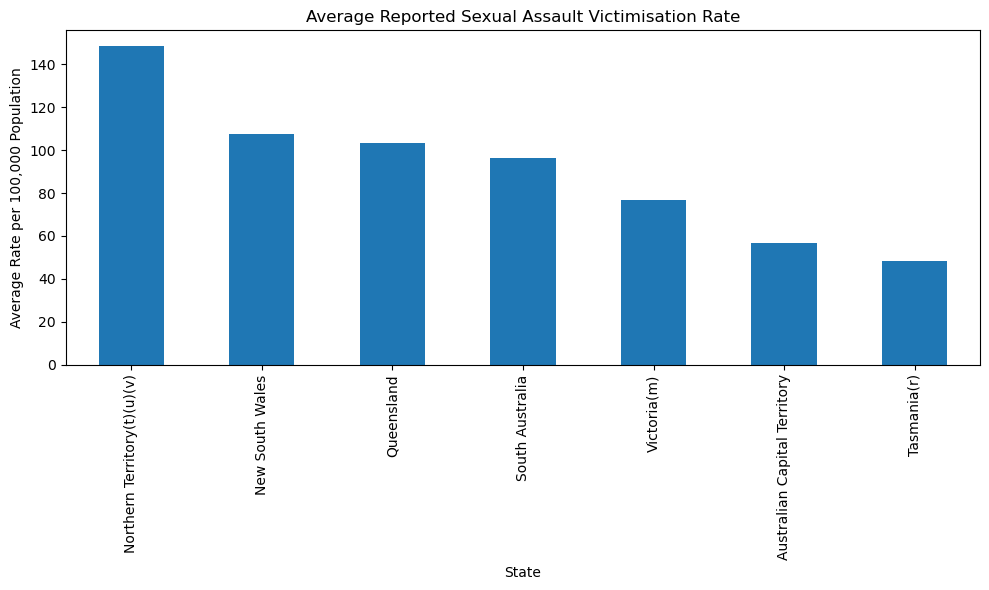

In [37]:
plt.figure(figsize=(10,6))
mean_rates.plot(kind="bar")

plt.title("Average Reported Sexual Assault Victimisation Rate")
plt.ylabel("Average Rate per 100,000 Population")

plt.tight_layout()

plt.savefig("../images/average_rate.png", dpi=300)

plt.show()

# Does the Average Tell the Whole Story?

The average provides one perspective on the data.

But our Medium article argued that averages often hide important information.

Let's investigate whether that's true for this dataset.

We'll calculate the variance of the reported victimisation rate for each state.

In [38]:
variance_rates = (
    sexual_assault_df
    .groupby("State")["Victimisation Rate"]
    .var()
    .sort_values(ascending=False)
)

variance_rates

State
New South Wales                 898.475766
Northern Territory(t)(u)(v)     567.048226
Queensland                      485.279839
Tasmania(r)                     453.905071
Australian Capital Territory    289.691250
Victoria(m)                     140.813185
South Australia                 106.657056
Name: Victimisation Rate, dtype: float64

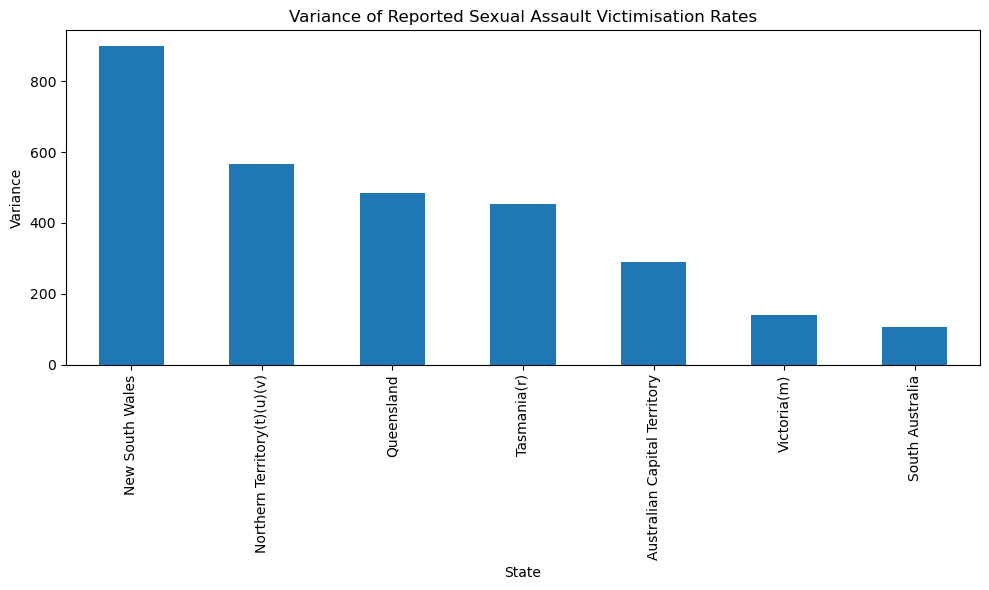

In [39]:
plt.figure(figsize=(10,6))

variance_rates.plot(kind="bar")

plt.title("Variance of Reported Sexual Assault Victimisation Rates")

plt.ylabel("Variance")

plt.tight_layout()

plt.savefig("../images/variance_by_state.png", dpi=300)

plt.show()

# Interpretation

The average tells us where the victimisation rates are centred.

Variance tells us how much those rates fluctuate over time.

A state with a high average but low variance experiences relatively consistent reported rates.

A state with a similar average but much higher variance has experienced much larger changes over the years.

This illustrates the central message of this project:

**Two datasets can have similar averages while telling very different statistical stories.**

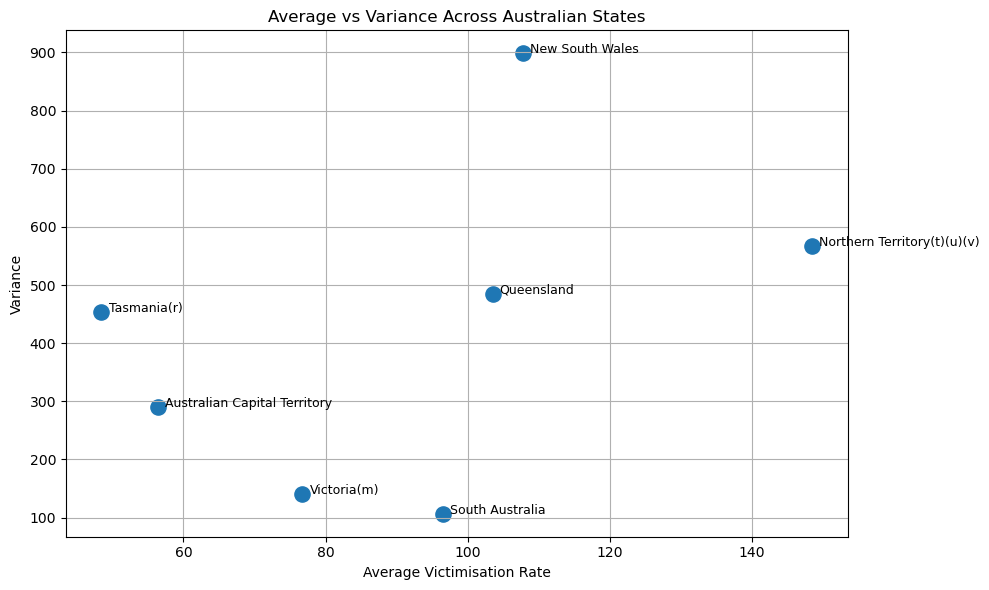

In [40]:
summary = (
    sexual_assault_df
    .groupby("State")["Victimisation Rate"]
    .agg(["mean", "var"])
    .reset_index()
)

plt.figure(figsize=(10,6))

plt.scatter(
    summary["mean"],
    summary["var"],
    s=120
)

for _, row in summary.iterrows():
    plt.text(
        row["mean"] + 1,
        row["var"],
        row["State"],
        fontsize=9
    )

plt.xlabel("Average Victimisation Rate")

plt.ylabel("Variance")

plt.title("Average vs Variance Across Australian States")

plt.grid(True)

plt.tight_layout()

plt.savefig("../images/mean_vs_variance.png", dpi=300)

plt.show()

When we began this notebook, we asked whether averages tell the whole story.

They don't.

By combining the mean with variance, we discovered that states with comparable average reported victimisation rates can experience very different levels of variability over time.

This is exactly why measures of spread are indispensable in statistics, they reveal patterns that measures of centre alone cannot.